# 二分类逻辑斯蒂回归

In [2]:
import torchvision
train_data = torchvision.datasets.MNIST(root ='./mnist/', train=True, download=True)
test_data = torchvision.datasets.MNIST(root = './mnist/', train = False, download = True)
# 在当前目录下新建一个mnist文件夹下载训练集和测试集

Failed to download (trying next):
HTTP Error 404: Not Found

Failed download. Trying https -> http instead. Downloading http://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz to ./mnist/MNIST\raw\train-images-idx3-ubyte.gz


100%|██████████| 9.91M/9.91M [01:47<00:00, 92.5kB/s]


Extracting ./mnist/MNIST\raw\train-images-idx3-ubyte.gz to ./mnist/MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 28.9MB/s]


Extracting ./mnist/MNIST\raw\train-labels-idx1-ubyte.gz to ./mnist/MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found

Failed download. Trying https -> http instead. Downloading http://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz to ./mnist/MNIST\raw\t10k-images-idx3-ubyte.gz


100%|██████████| 1.65M/1.65M [00:07<00:00, 224kB/s] 


Extracting ./mnist/MNIST\raw\t10k-images-idx3-ubyte.gz to ./mnist/MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<00:00, 589kB/s]

Extracting ./mnist/MNIST\raw\t10k-labels-idx1-ubyte.gz to ./mnist/MNIST\raw



In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
x_data = torch.tensor([[1.],[2.],[3.]]) # 一般用tensor而非Tensor（一般用于创建已知形状的空白张量）
# 判断张量维度看最多有几重[]
y_data = torch.tensor([[0.],[0.],[1.]])

class LogisticRegressionModel(torch.nn.Module):
    def __init__(self):
        super(LogisticRegressionModel, self).__init__()
        self.linear = torch.nn.Linear(1, 1) # 第一个计算块还是xw+b

    def forward(self, x):
        y_pred = torch.sigmoid(self.linear(x)) # sigmoid激活函数
        return y_pred

model = LogisticRegressionModel()
criterion = torch.nn.BCELoss(reduction="sum") # 换成BCE损失函数
optimizer = torch.optim.SGD(model.parameters(), lr=0.01) 

for epoch in range(1000):
    y_pred = model(x_data)
    loss = criterion(y_pred, y_data)
    print("epoch:", epoch, "loss:", loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

epoch: 0 loss: 2.1107375621795654
epoch: 1 loss: 2.091179370880127
epoch: 2 loss: 2.07285737991333
epoch: 3 loss: 2.0557003021240234
epoch: 4 loss: 2.039639711380005
epoch: 5 loss: 2.024609327316284
epoch: 6 loss: 2.010545492172241
epoch: 7 loss: 1.9973866939544678
epoch: 8 loss: 1.9850742816925049
epoch: 9 loss: 1.9735525846481323
epoch: 10 loss: 1.9627685546875
epoch: 11 loss: 1.952671766281128
epoch: 12 loss: 1.9432144165039062
epoch: 13 loss: 1.934352159500122
epoch: 14 loss: 1.9260425567626953
epoch: 15 loss: 1.918245792388916
epoch: 16 loss: 1.9109251499176025
epoch: 17 loss: 1.9040449857711792
epoch: 18 loss: 1.897573709487915
epoch: 19 loss: 1.8914803266525269
epoch: 20 loss: 1.8857369422912598
epoch: 21 loss: 1.880317211151123
epoch: 22 loss: 1.8751963376998901
epoch: 23 loss: 1.8703515529632568
epoch: 24 loss: 1.8657622337341309
epoch: 25 loss: 1.8614088296890259
epoch: 26 loss: 1.8572726249694824
epoch: 27 loss: 1.8533371686935425
epoch: 28 loss: 1.849587082862854
epoch: 29 

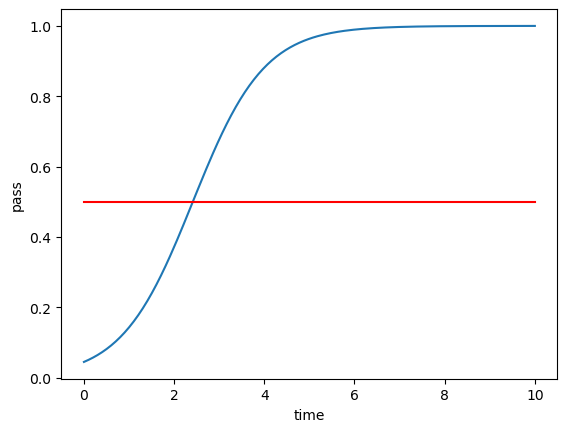

In [ ]:
# 手动创建一组模拟测试集
x = np.linspace(0, 10, 200) # 0-10之间等差数列，共200个数
x_t = torch.Tensor(x).view((200,1)) # 转换成200行1列的矩阵
y_t = model(x_t)
y = y_t.data.numpy() # 将y_t转换成numpy数组
plt.plot(x, y)
plt.plot([0,10],[0.5,0.5],c="r") # 绘制(0,0.5)到(10,0.5)的直线
plt.xlabel("time")
plt.ylabel("pass")
plt.show()
# 下图展示了输入不同x进入模型预算后，得到的y_hat（真实y为1的概率）